# MERFISH 300k

- Creator: Mohammad Vali Sanian (mohammad.sanian@helsinki.fi; mv10@sanger.ac.uk)
- Date of Creation: 16.08.2024
- Date of Last Modification: 14.09.2024 (by Sebastian Birk; sb75@sanger.ac.uk)

# 1. Setup

## 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [3]:
import os
import logging

import anndata as ad
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from sklearn.model_selection import train_test_split

from nichejepa.datasets import prepare_dataset
from nichejepa.infer import infer
from nichejepa.train import train
from nichejepa.utils.config import create_params_from_YAML_wandb_config
from nichejepa.utils.distributed import init_distributed
from nichejepa.utils.evaluation import clustering_metrics, classification_metrics

from analysis_utils import *

## 1.2 Load Config/Params
All setup will be done in the config file. Please edit that file to continue.

In [8]:
rank=0
logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)
params = create_params_from_YAML_wandb_config('../../../nichejepa/configs/merfish_300k.yaml',logger)

INFO:root:Loaded parameters from YAML file.


In [21]:
params

{'data': {'batch_size': 32,
  'data_path': '/lustre/scratch126/cellgen/team361/am84/NicheJEPA/datasets/am84/st_data/gold/cell-neighborhood-tokenizer/merfish_mouse_brain_300k/16-shards/merfish_mouse_brain_300k_4_False_read_depth_shifted_log_2170.dataset',
  'split': 0.2,
  'stratify': False,
  'data_set_name': 'merfish_300k',
  'num_workers': 18,
  'pin_mem': True,
  'vocab_size': 1087,
  'seq_len_cell': 411,
  'seq_len_neighborhood': 809,
  'has_cls': True,
  'random_state': 0,
  'sample_subset': False},
 'logging': {'write_tag': 'jepa'},
 'mask': {'context_mask_size': 1240,
  'target_mask_size': 10,
  'n_contexts': 1,
  'n_targets': 9,
  'per_segment_mask_ratio': 0.2,
  'segment_masking': True},
 'meta': {'enc_depth': 3,
  'load_checkpoint': False,
  'pred_depth': 1,
  'pred_emb_dim': 768,
  'enc_emb_dim': 768,
  'enc_pred_depth': 31,
  'top_k': 127,
  'read_checkpoint': None,
  'use_bfloat16': True,
  'pos_learnable': False,
  'seg_learnable': False},
 'optimization': {'epochs': 40,


In [29]:
save_folder = f"logs/{params['data']['data_set_name']}_" \
              f"pred_depth_{params['meta']['pred_depth']}_pred_emb_dim_{params['meta']['pred_emb_dim']}_" \
              f"enc_depth_{params['meta']['enc_depth']}_enc_emb_dim_{params['meta']['enc_emb_dim']}_n_targets_{params['mask']['n_targets']}_" \
              f"n_contexts_{params['mask']['n_contexts']}_target_mask_size_{params['mask']['target_mask_size']}_" \
              f"context_mask_size_{params['mask']['context_mask_size']}_num_epochs_{params['optimization']['epochs']}_" \
              f"seq_len_cell_{params['data']['seq_len_cell']}_" \
              f"seq_len_neighborhood_{params['data']['seq_len_neighborhood']}_" \
              f"pos_learnable_{params['meta']['pos_learnable']}_" \
              f"seg_learnable_{params['meta']['seg_learnable']}_" \
              f"ratio_{params['mask']['per_segment_mask_ratio']}"

## 1.3 Create Train & Test Dataset

In [10]:
train_dataset, test_dataset = prepare_dataset(params)
train_dataset

Dataset({
    features: ['gene_tokens_cell', 'gene_tokens_neighborhood', 'cell_types', 'niche_types', 'donor_id', 'sample_id', 'batch_id', 'n_nonzero_cell_tokens', 'n_nonzero_neighborhood_tokens', 'n_nonzero_tokens', 'input_ids'],
    num_rows: 249764
})

## 1.4 Run INIT Distributed

In [11]:
devices=['cuda:0']
world_size=1
os.environ['CUDA_VISIBLE_DEVICES'] = str(devices[rank].split(':')[-1])

logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

world_size, rank = init_distributed(rank_and_world_size=(rank, world_size), port=40310)
logger.info(f'Running... (rank: {rank}/{world_size})')

INFO:root:Running... (rank: 0/1)


# 2. Model Training

In [ ]:
# Train model
train(params, train_dataset, test_dataset)

# 3. Analysis

## 3.1 Run Model Inference

In [ ]:
#dataset = prepare_dataset(params,
#                          split_dataset=False)
#dataset

In [12]:
# Run model inference
adata = infer(params,
              train_dataset,
              agg_type='avg', # 'weighted_avg', 'cls'
              cell_gene_ids=[10],
              neighborhood_gene_ids=[])

# Save adata
adata.write(f'{save_folder}/adata.h5ad')

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1088, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)
INFO:root:Data loader created.


/lustre/scratch126/cellgen/team205/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/torch/utils/data/dataloader.py:557: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(
/lustre/scratch126/cellgen/team205/sb75/nichejepa/src/nichejepa/helper.py:79: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `we

INFO:root:Loaded pretrained encoder from epoch 18 with msg: <All keys matched successfully>.
INFO:root:Loaded pretrained predictor from epoch 18 with msg: <All keys matched successfully>.
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:Loaded pretrained target encoder from epoch 18 with msg: <All keys matched successfully>.
INFO:root:Finished loading checkpoint with read path: logs/merfish_300k_pred_depth_1_pred_emb_dim_768_enc_depth_3_enc_emb_dim_768_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_411_seq_len_neighborhood_809_pos_learnable_False_seg_learnable_False_ratio_0.2/jepa-latest.pth.tar.


0it [00:00, ?it/s]/lustre/scratch126/cellgen/team205/sb75/nichejepa/src/nichejepa/infer.py:243: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.bfloat16,
7806it [16:41,  7.79it/s]
/lustre/scratch126/cellgen/team205/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


(249764, 768)
(249764, 768)
(249764, 768)


In [31]:
adata = sc.read_h5ad(f'{save_folder}/adata.h5ad')

## 3.2 Plot Embeddings

/lustre/scratch126/cellgen/team205/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/lustre/scratch126/cellgen/team205/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


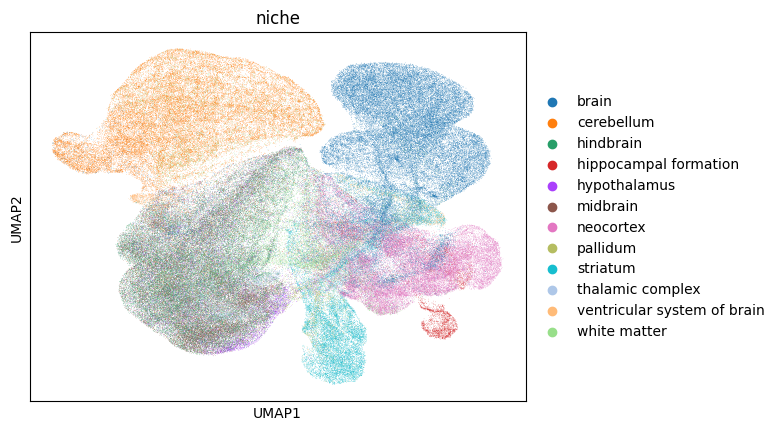

In [32]:
# Plot (aggregated) neighborhood gene embeddings
label = 'niche'
layer = 2

sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb_layer_{layer}')
sc.tl.umap(adata)
sc.pl.umap(adata, color=label)

/lustre/scratch126/cellgen/team205/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/lustre/scratch126/cellgen/team205/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


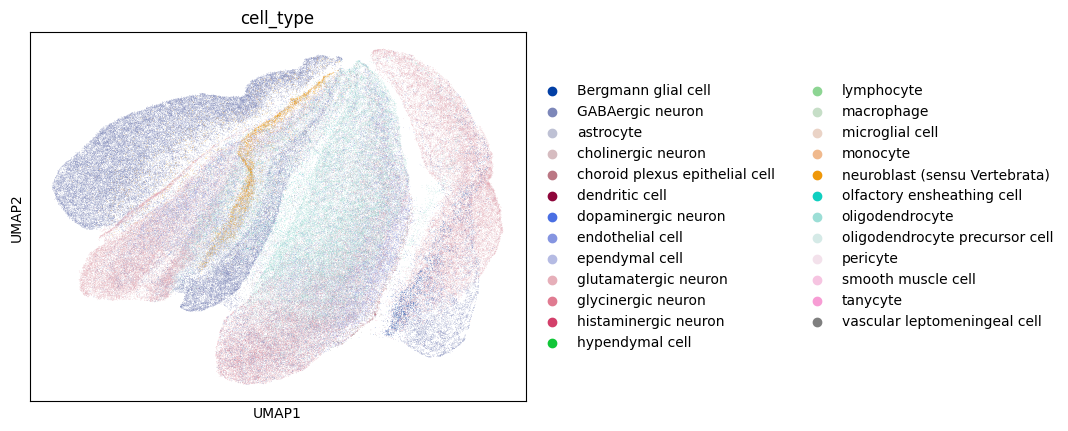

In [36]:
# Plot cell gene embedding for a specifc gene
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='cell_emb_layer_2')
sc.tl.umap(adata)
sc.pl.umap(adata, color='cell_type')

/lustre/scratch126/cellgen/team205/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/lustre/scratch126/cellgen/team205/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


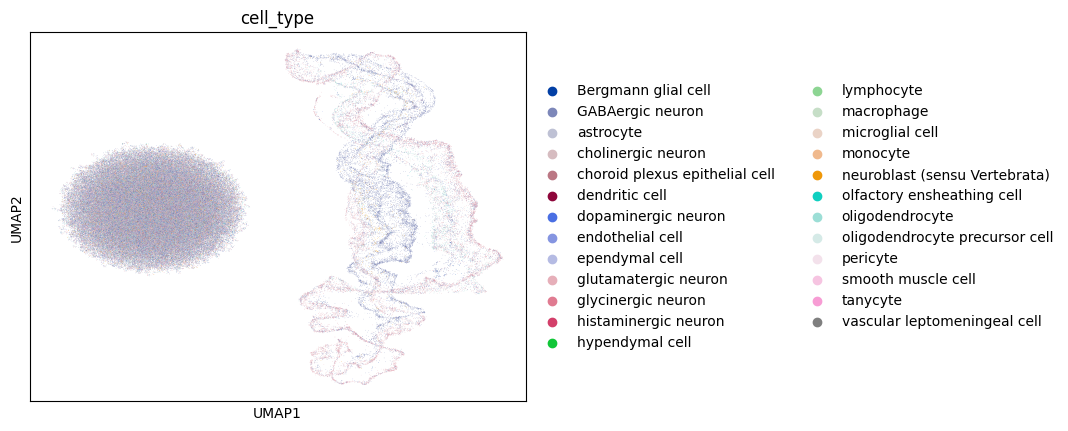

In [33]:
# Plot (aggregated) cell gene embeddings 
label = 'cell_type'
gene_id = 10

sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb_gene{gene_id}')
sc.tl.umap(adata)
sc.pl.umap(adata, color=label)

## 3.3 Plot Embedding Similarity Stats

       Class 1                     Class 2  Mean Similarity  \
0    astrocyte                   astrocyte         0.617938   
1    astrocyte        glutamatergic neuron         0.552532   
2    astrocyte             microglial cell         0.603200   
3    astrocyte                    pericyte         0.611047   
4    astrocyte             oligodendrocyte         0.615488   
..         ...                         ...              ...   
620   tanycyte  olfactory ensheathing cell         0.593286   
621   tanycyte          cholinergic neuron         0.360758   
622   tanycyte             hypendymal cell         0.613623   
623   tanycyte                    monocyte         0.580701   
624   tanycyte                    tanycyte         0.720152   

     Variance Similarity  
0               0.051539  
1               0.051480  
2               0.050701  
3               0.051764  
4               0.049483  
..                   ...  
620             0.036372  
621             0.058030  


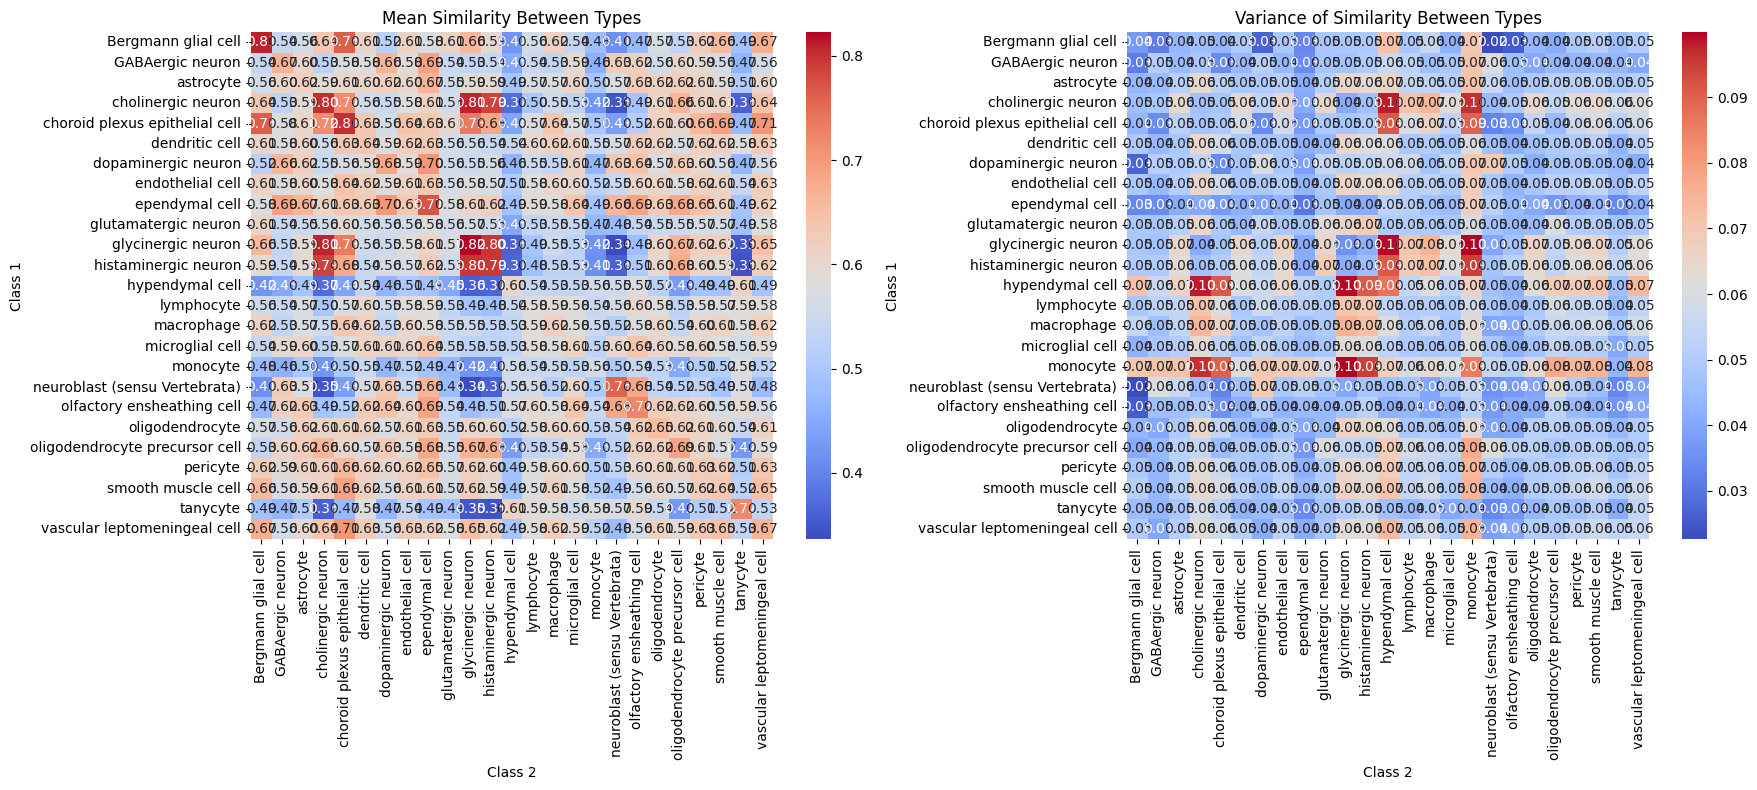

In [38]:
similarity_stats = compute_similarity_stats(
    adata,
    n_samples=None,
    type_key='cell_type',
    embedding_key='cell_emb_layer_2')
plot_similarity_heatmaps(similarity_stats)

## 3.4 Compute Metrics

In [ ]:
# NMI & ARI for cell types (cell embedding)
clustering_metrics(adata,
                   emb_key='cell_emb_layer_2',
                   label_col='cell_type')

In [ ]:
# NMI & ARI for niche (neighborhood embedding)
clustering_metrics(adata,
                   emb_key='neighborhood_emb_layer_2',
                   label_col='niche')

## 3.5 Plot Loss Curve

In [46]:
df['loss']

0         0.52338
1         0.50363
2         0.48740
3         0.47330
4         0.46124
           ...   
147470    0.04594
147471    0.04556
147472    0.04631
147473    0.04618
147474    0.04794
Name: loss, Length: 147475, dtype: object

/tmp/ipykernel_2501510/2056519582.py:1: DtypeWarning: Columns (0,1,2,3,4,5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(f'{save_folder}/jepa_r0.csv')


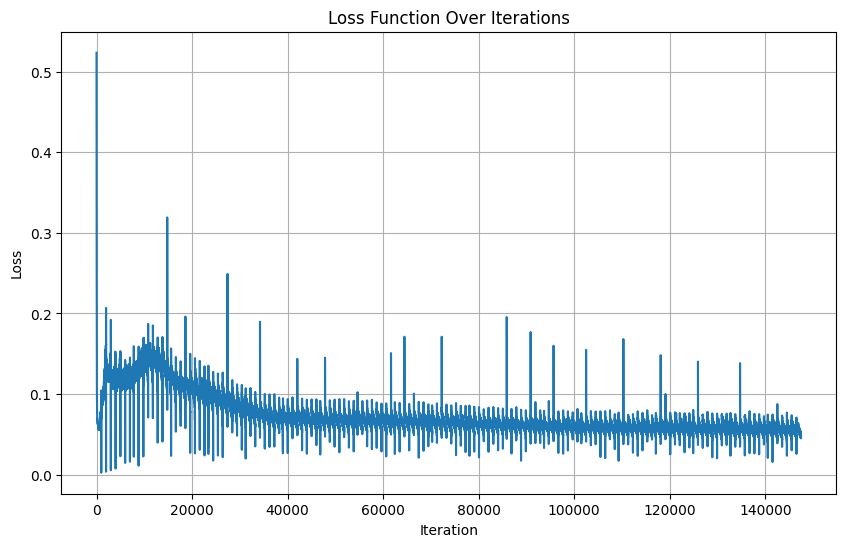

In [47]:
df = pd.read_csv(f'{save_folder}/jepa_r0.csv')
df['loss'] = pd.to_numeric(df['loss'], errors='coerce')

plt.figure(figsize=(10, 6))
plt.plot(df.index,df['loss'])
plt.title('Loss Function Over Iterations')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.grid(True)
plt.show()